<a href="https://colab.research.google.com/github/zainulabideen3203-ResearckWork/Mphil_thesis/blob/main/predictiondataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Step 0. Import libraries**

**Step 1. Load the data**

**Step 2. Explore the data (EDA)**

**Step 3. Clean the data (remove duplicates)**

**Step 4. Split into train and test sets**

**Step 5. Scale the features (fit on the training data only)**

**Step 6. Handle the class imbalance (nothing vs class weights vs SMOTE)**

**Step 7. Train the 5 models with tuning and cross-validation**

**Step 8. Evaluate (Accuracy, Precision, Recall, F1, AUC)**

**Step 9. Run a statistical significance test**

**Step 10. Explain the best model with SHAP**

**Step 11. Save the tables and graphs**

**Step 0. Import libraries**

In [17]:
!pip install -q xgboost imbalanced-learn shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from scipy import stats
import shap
import time

**GDrive Mount**

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Step 1. Load the data**

In [7]:
path = "/content/drive/MyDrive/diabetes_binary_health_indicators_BRFSS2015.csv"
df = pd.read_csv(path)

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Diabetes_binary"].value_counts())
df.head()

Shape: (253680, 22)
Missing values: 0
Duplicate rows: 24206
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


**Explore the data**

In [8]:
print("Diabetic %:", round(df["Diabetes_binary"].mean() * 100, 2))
df.describe().T.round(2)

Diabetic %: 13.93


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.14,0.35,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.43,0.49,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.96,0.19,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.44,0.50,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.04,0.20,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.76,0.43,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.63,0.48,0.0,0.0,1.0,1.0,1.0


**class balance and summary statistics**

In [9]:
print("Diabetic %:", round(df["Diabetes_binary"].mean() * 100, 2))
df.describe().T.round(2)

Diabetic %: 13.93


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.14,0.35,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.43,0.49,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.96,0.19,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.44,0.50,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.04,0.20,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.76,0.43,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.63,0.48,0.0,0.0,1.0,1.0,1.0


**class imbalance plot**

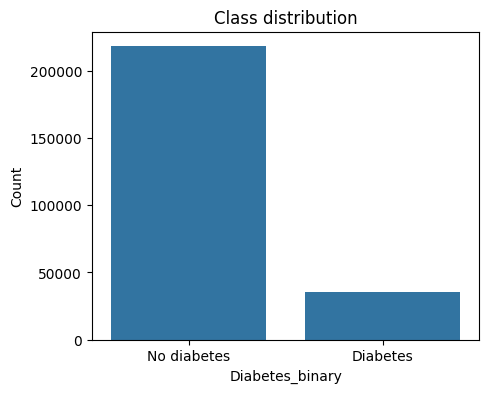

In [10]:
plt.figure(figsize=(5, 4))
sns.countplot(x="Diabetes_binary", data=df)
plt.title("Class distribution")
plt.xticks([0, 1], ["No diabetes", "Diabetes"])
plt.ylabel("Count")
plt.show()

**Main features differ between the two groups**

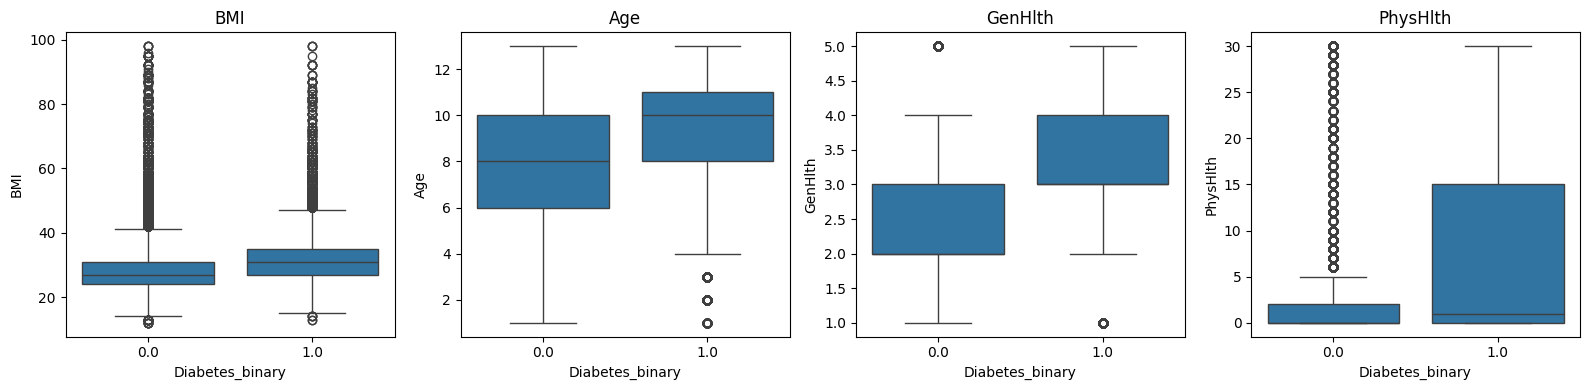

In [11]:
cols = ["BMI", "Age", "GenHlth", "PhysHlth"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(x="Diabetes_binary", y=c, data=df, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Correlation**

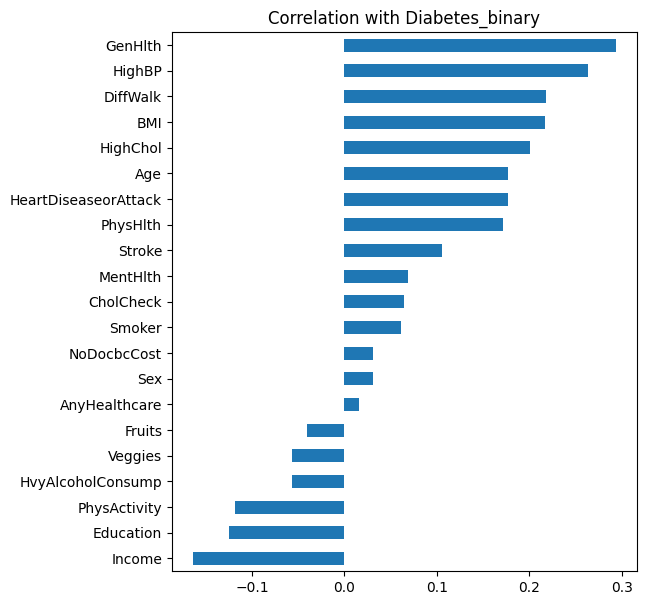

,Diabetes_binary
Income,-0.163919
Education,-0.124456
PhysActivity,-0.118133
HvyAlcoholConsump,-0.057056
Veggies,-0.056584
Fruits,-0.040779
AnyHealthcare,0.016255
Sex,0.031430
NoDocbcCost,0.031433
Smoker,0.060789


In [12]:
corr = df.corr()["Diabetes_binary"].drop("Diabetes_binary").sort_values()
plt.figure(figsize=(6, 7))
corr.plot(kind="barh")
plt.title("Correlation with Diabetes_binary")
plt.show()
corr

**Remove duplicate Data**

In [13]:
print("Before:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After: ", df.shape)
print("Diabetic %:", round(df["Diabetes_binary"].mean() * 100, 2))

Before: (253680, 22)
After:  (229474, 22)
Diabetic %: 15.29


**Split into train and test**

In [14]:
X = df.drop(columns="Diabetes_binary")
y = df["Diabetes_binary"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Diabetic % in train:", round(y_train.mean() * 100, 2))
print("Diabetic % in test: ", round(y_test.mean() * 100, 2))

Train: (183579, 21) | Test: (45895, 21)
Diabetic % in train: 15.29
Diabetic % in test:  15.29


**scale the features**

In [15]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),      columns=X.columns, index=X_test.index)

print(X_train_s.mean().round(2).head(5).to_dict())
print(X_train_s.std().round(2).head(5).to_dict())

{'HighBP': 0.0, 'HighChol': 0.0, 'CholCheck': 0.0, 'BMI': -0.0, 'Smoker': -0.0}
{'HighBP': 1.0, 'HighChol': 1.0, 'CholCheck': 1.0, 'BMI': 1.0, 'Smoker': 1.0}


**prepare the three imbalance strategies**

In [16]:
# Strategy A: do nothing (use X_train_s, y_train as they are)

# Strategy B: class weights (applied inside each model later)
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos   # used by XGBoost
print("Class weight ratio (neg/pos):", round(scale_pos_weight, 2))

# Strategy C: SMOTE (training data only)
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_s, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_sm.value_counts().to_dict())

Class weight ratio (neg/pos): 5.54
Before SMOTE: {0: 155501, 1: 28078}
After SMOTE:  {0: 155501, 1: 155501}


**train and test all models**

In [18]:
def get_models(strategy):
    cw = "balanced" if strategy == "Class weights" else None
    spw = scale_pos_weight if strategy == "Class weights" else 1
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight=cw),
        "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                                n_jobs=-1, random_state=42, class_weight=cw),
        "SVM (Linear)": LinearSVC(class_weight=cw, max_iter=2000, random_state=42),
        "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                                 eval_metric="logloss", n_jobs=-1, random_state=42,
                                 scale_pos_weight=spw),
        "ANN": MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                             max_iter=100, random_state=42),
    }
    if strategy == "Class weights":
        models.pop("ANN")   # MLPClassifier has no class-weight option
    return models

strategies = {
    "No handling":   (X_train_s, y_train),
    "Class weights": (X_train_s, y_train),
    "SMOTE":         (X_train_sm, y_train_sm),
}

results = []
for strat, (Xtr, ytr) in strategies.items():
    for name, model in get_models(strat).items():
        t0 = time.time()
        model.fit(Xtr, ytr)
        pred = model.predict(X_test_s)
        score = model.decision_function(X_test_s) if hasattr(model, "decision_function") \
                else model.predict_proba(X_test_s)[:, 1]
        results.append({
            "Strategy": strat, "Model": name,
            "Accuracy":  accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall":    recall_score(y_test, pred),
            "F1":        f1_score(y_test, pred),
            "AUC":       roc_auc_score(y_test, score),
            "Time (s)":  round(time.time() - t0, 1),
        })
        print(f"done: {strat} | {name} ({round(time.time() - t0)}s)")

res = pd.DataFrame(results).round(4)
res.to_csv("/content/drive/MyDrive/results_first_pass.csv", index=False)
res.sort_values("AUC", ascending=False)

done: No handling | Logistic Regression (1s)
done: No handling | Random Forest (49s)
done: No handling | SVM (Linear) (1s)
done: No handling | XGBoost (10s)
done: No handling | ANN (16s)
done: Class weights | Logistic Regression (1s)
done: Class weights | Random Forest (21s)
done: Class weights | SVM (Linear) (1s)
done: Class weights | XGBoost (12s)
done: SMOTE | Logistic Regression (1s)
done: SMOTE | Random Forest (58s)
done: SMOTE | SVM (Linear) (1s)
done: SMOTE | XGBoost (13s)
done: SMOTE | ANN (45s)


,Strategy,Model,Accuracy,Precision,Recall,F1,AUC,Time (s)
4,No handling,ANN,0.8539,0.5817,0.1597,0.2506,0.8172,15.8
12,SMOTE,XGBoost,0.8544,0.5729,0.1892,0.2845,0.8170,13.3
3,No handling,XGBoost,0.8546,0.5818,0.1764,0.2707,0.8162,10.4
8,Class weights,XGBoost,0.7139,0.3202,0.7753,0.4533,0.8147,11.8
1,No handling,Random Forest,0.8544,0.6056,0.1376,0.2243,0.8119,49.3
6,Class weights,Random Forest,0.7807,0.3706,0.6217,0.4644,0.8109,20.9
5,Class weights,Logistic Regression,0.7143,0.3183,0.7601,0.4487,0.8106,0.7
7,Class weights,SVM (Linear),0.7104,0.3155,0.7645,0.4467,0.8103,0.7
2,No handling,SVM (Linear),0.8509,0.6053,0.0712,0.1275,0.8102,0.7
0,No handling,Logistic Regression,0.8505,0.5398,0.1537,0.2393,0.8102,1.2


**paper-ready tables and chart**


Accuracy
Strategy             Class weights  No handling   SMOTE
Model                                                  
ANN                            NaN       0.8539  0.7347
Logistic Regression         0.7143       0.8505  0.7154
Random Forest               0.7807       0.8544  0.8362
SVM (Linear)                0.7104       0.8509  0.7104
XGBoost                     0.7139       0.8546  0.8544

Recall
Strategy             Class weights  No handling   SMOTE
Model                                                  
ANN                            NaN       0.1597  0.6773
Logistic Regression         0.7601       0.1537  0.7568
Random Forest               0.6217       0.1376  0.3740
SVM (Linear)                0.7645       0.0712  0.7645
XGBoost                     0.7753       0.1764  0.1892

F1
Strategy             Class weights  No handling   SMOTE
Model                                                  
ANN                            NaN       0.2506  0.4385
Logistic Regression       

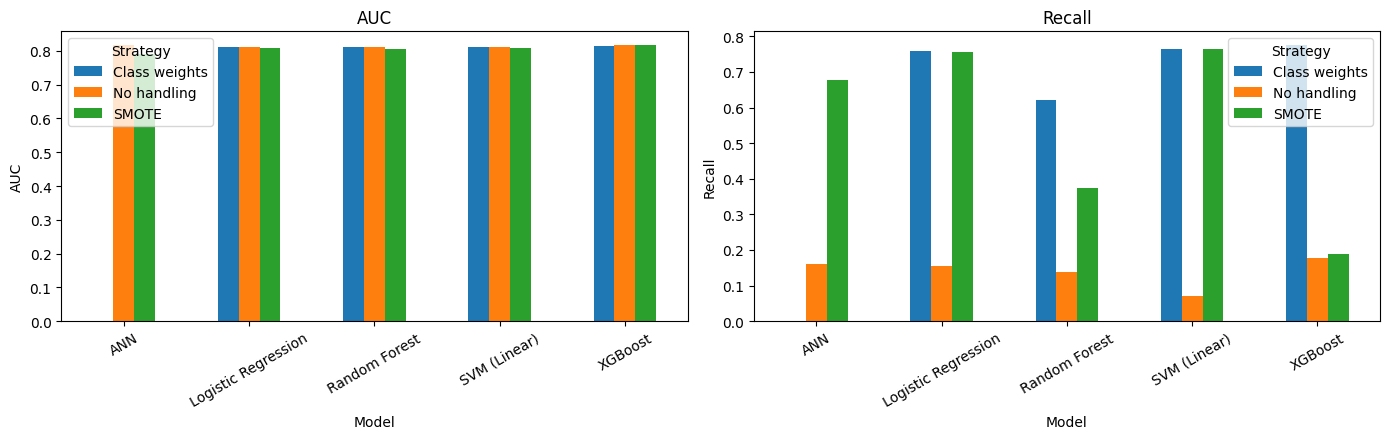

In [19]:
# One table per metric: rows = models, columns = imbalance strategy
for metric in ["Accuracy", "Recall", "F1", "AUC"]:
    print(f"\n{metric}")
    print(res.pivot(index="Model", columns="Strategy", values=metric).round(4))

# Chart: AUC and Recall side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["AUC", "Recall"]):
    res.pivot(index="Model", columns="Strategy", values=metric).plot(kind="bar", ax=ax)
    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/results_chart.png", dpi=300)
plt.show()

**tune XGBoost and Random Forest**

In [20]:
from sklearn.model_selection import RandomizedSearchCV

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# XGBoost
xgb_search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=42,
                  scale_pos_weight=scale_pos_weight),
    param_distributions={
        "n_estimators": [200, 300, 500],
        "max_depth": [4, 6, 8],
        "learning_rate": [0.03, 0.05, 0.1],
        "subsample": [0.7, 0.9, 1.0],
        "colsample_bytree": [0.7, 0.9, 1.0],
        "min_child_weight": [1, 5, 10],
    },
    n_iter=8, scoring="roc_auc", cv=cv, random_state=42, n_jobs=1, verbose=1,
)
xgb_search.fit(X_train_s, y_train)
print("XGBoost best AUC (CV):", round(xgb_search.best_score_, 4))
print("XGBoost best params:", xgb_search.best_params_)

# Random Forest
rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=42, class_weight="balanced_subsample"),
    param_distributions={
        "n_estimators": [100, 200],
        "max_depth": [10, 20, None],
        "min_samples_leaf": [1, 5, 10],
        "max_features": ["sqrt", 0.5],
    },
    n_iter=8, scoring="roc_auc", cv=cv, random_state=42, n_jobs=1, verbose=1,
)
rf_search.fit(X_train_s, y_train)
print("RF best AUC (CV):", round(rf_search.best_score_, 4))
print("RF best params:", rf_search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
XGBoost best AUC (CV): 0.8154
XGBoost best params: {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Fitting 3 folds for each of 8 candidates, totalling 24 fits
RF best AUC (CV): 0.8112
RF best params: {'n_estimators': 100, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 20}


**final models on the test set**

In [21]:
final = {
    "Logistic Regression":   LogisticRegression(max_iter=1000, class_weight="balanced"),
    "SVM (Linear)":          LinearSVC(class_weight="balanced", max_iter=2000, random_state=42),
    "Random Forest (tuned)": rf_search.best_estimator_,
    "XGBoost (tuned)":       xgb_search.best_estimator_,
    "ANN":                   MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                           max_iter=100, random_state=42),
}

scores, rows = {}, []
for name, m in final.items():
    if name in ["Logistic Regression", "SVM (Linear)", "ANN"]:
        m.fit(X_train_s, y_train)          # tuned RF and XGBoost are already fitted
    pred = m.predict(X_test_s)
    s = m.decision_function(X_test_s) if hasattr(m, "decision_function") \
        else m.predict_proba(X_test_s)[:, 1]
    scores[name] = s
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall":    recall_score(y_test, pred),
                 "F1":        f1_score(y_test, pred),
                 "AUC":       roc_auc_score(y_test, s)})

final_res = pd.DataFrame(rows).round(4)
final_res.to_csv("/content/drive/MyDrive/results_final.csv", index=False)
final_res

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.7143,0.3183,0.7601,0.4487,0.8106
1,SVM (Linear),0.7104,0.3155,0.7645,0.4467,0.8103
2,Random Forest (tuned),0.7514,0.3459,0.7020,0.4634,0.8152
3,XGBoost (tuned),0.7069,0.3168,0.7926,0.4526,0.8195
4,ANN,0.8539,0.5817,0.1597,0.2506,0.8172


**AUC differences**

In [22]:
rng = np.random.default_rng(42)
y_arr = y_test.values
n = len(y_arr)
B = 500

boot = {k: [] for k in scores}
for _ in range(B):
    idx = rng.integers(0, n, n)
    if y_arr[idx].min() == y_arr[idx].max():
        continue
    for k, s in scores.items():
        boot[k].append(roc_auc_score(y_arr[idx], s[idx]))
boot = {k: np.array(v) for k, v in boot.items()}

print("AUC with 95% CI")
for k, v in boot.items():
    print(f"{k:24s} {np.mean(v):.4f}  [{np.percentile(v, 2.5):.4f}, {np.percentile(v, 97.5):.4f}]")

best = "XGBoost (tuned)"
print(f"\nDifference vs {best} (positive = {best} is better)")
for k, v in boot.items():
    if k == best:
        continue
    d = boot[best] - v
    lo, hi = np.percentile(d, [2.5, 97.5])
    verdict = "significant" if (lo > 0 or hi < 0) else "NOT significant"
    print(f"{k:24s} diff={d.mean():+.4f}  [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")

AUC with 95% CI
Logistic Regression      0.8106  [0.8063, 0.8155]
SVM (Linear)             0.8104  [0.8061, 0.8153]
Random Forest (tuned)    0.8152  [0.8106, 0.8201]
XGBoost (tuned)          0.8196  [0.8152, 0.8243]
ANN                      0.8172  [0.8124, 0.8218]

Difference vs XGBoost (tuned) (positive = XGBoost (tuned) is better)
Logistic Regression      diff=+0.0089  [+0.0075, +0.0104]  -> significant
SVM (Linear)             diff=+0.0092  [+0.0077, +0.0106]  -> significant
Random Forest (tuned)    diff=+0.0044  [+0.0032, +0.0054]  -> significant
ANN                      diff=+0.0023  [+0.0011, +0.0035]  -> significant


**SHAP plots for tuned XGBoost**

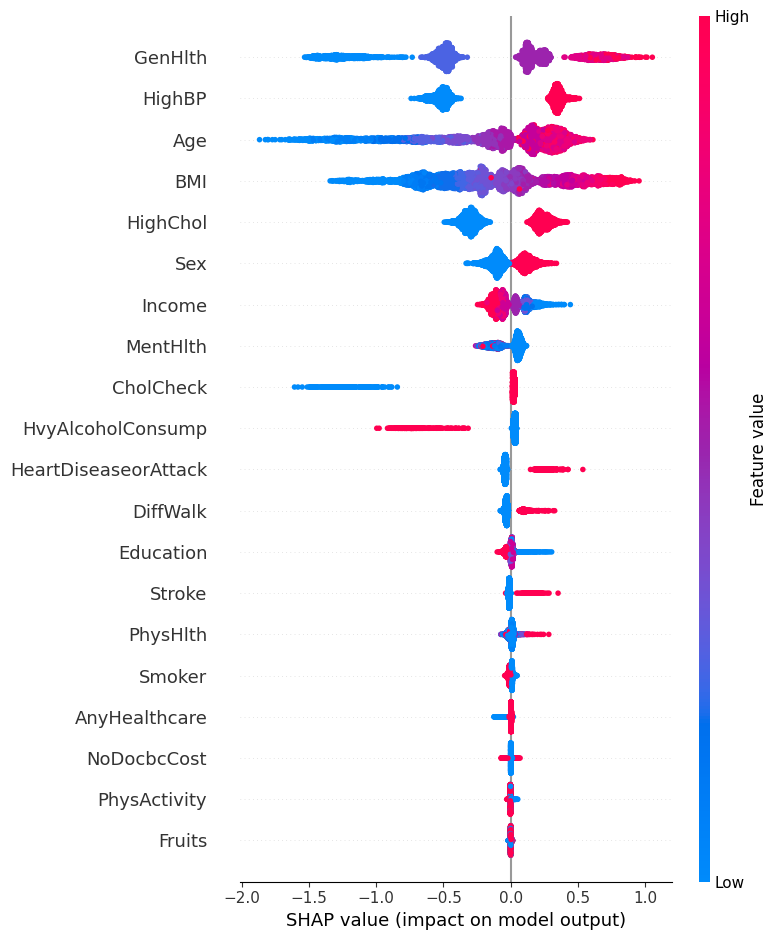

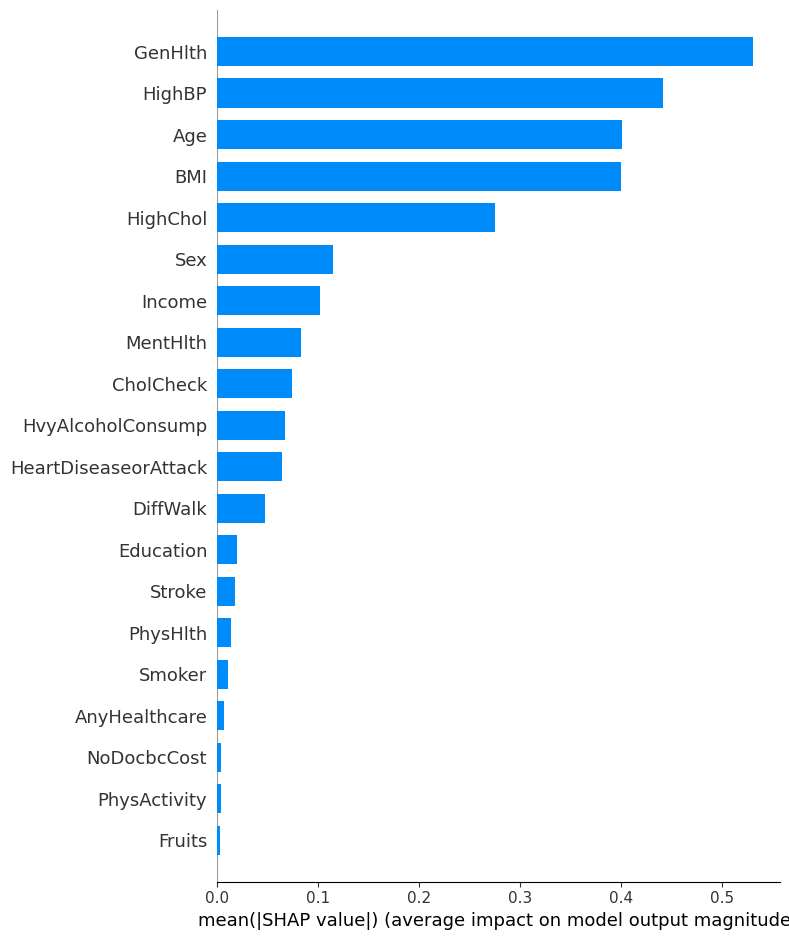

GenHlth              0.5311
HighBP               0.4417
Age                  0.4015
BMI                  0.4004
HighChol             0.2756
Sex                  0.1153
Income               0.1023
MentHlth             0.0830
CholCheck            0.0739
HvyAlcoholConsump    0.0675
dtype: float32


In [23]:
explainer = shap.TreeExplainer(xgb_search.best_estimator_)
sample = X_test_s.sample(5000, random_state=42)
sv = explainer.shap_values(sample)

# 1) Which features matter most, and in which direction
plt.figure()
shap.summary_plot(sv, sample, show=False)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

# 2) Simple ranking of feature importance
plt.figure()
shap.summary_plot(sv, sample, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/shap_bar.png", dpi=300, bbox_inches="tight")
plt.show()

# 3) Top 10 features as numbers
imp = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns).sort_values(ascending=False)
print(imp.head(10).round(4))